# Week 5: Exploratory data analysis and visualization

[Open in Colab](https://colab.research.google.com/github/WSU-EconS431/site/blob/main/weeks/week05.ipynb) · [View on GitHub](https://github.com/WSU-EconS431/site/blob/main/weeks/week05.ipynb)

Last week you loaded and reshaped tables. This week you use them to **find out what the data say**: how a variable is distributed, how it moves over time, how groups differ, and how two variables relate. Exploratory analysis is a loop of questions and quick figures, followed by a few figures built to be read by someone else. The reading, [FC 2. Long-Run Growth](https://intro.quantecon.org/long_run_growth.html), asks the same kind of questions of the same Maddison data.

**After this week you can:**

- check a new dataset for problems before drawing anything
- choose a figure for the question: histogram, line, scatter, or points by group
- use a log scale when percentage changes matter, and say so on the axis
- add context to a time-series figure (shaded recessions, a reference line)
- state a finding in one sentence with a number and a caveat

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter, NullFormatter
from IPython.display import Markdown, display
from pathlib import Path

DATA = "../data" if Path("../data").exists() else "https://raw.githubusercontent.com/WSU-EconS431/site/main/data"

mpd = pd.read_csv(f"{DATA}/mpd2020_full.csv")
mpd.loc[mpd["gdppc"] <= 0, "gdppc"] = np.nan        # zeros are placeholders (Week 4)
groups = pd.read_csv(f"{DATA}/country_groups.csv")

## 1. Look before you plot

Week 4's habits, as a routine you can run on any new table: the shape, the types, how much is missing, and whether the key columns identify rows uniquely.

In [2]:
def quick_look(df, keys):
    """Print the basic facts to check before analyzing a table."""
    print("rows, columns:", df.shape)
    print("duplicate keys:", df.duplicated(keys).sum())
    print("share missing:")
    print(df.isna().mean().round(3).to_string())

quick_look(mpd, ["countrycode", "year"])

rows, columns: (21682, 5)
duplicate keys: 0
share missing:
countrycode    0.000
country        0.000
year           0.000
gdppc          0.091
pop            0.207


No duplicate country-years, and the gaps are in `gdppc` and `pop`, as we saw. Now to the questions.

## 2. One variable: its distribution

How unequal are countries' incomes today? A **histogram** counts countries in bins of income:

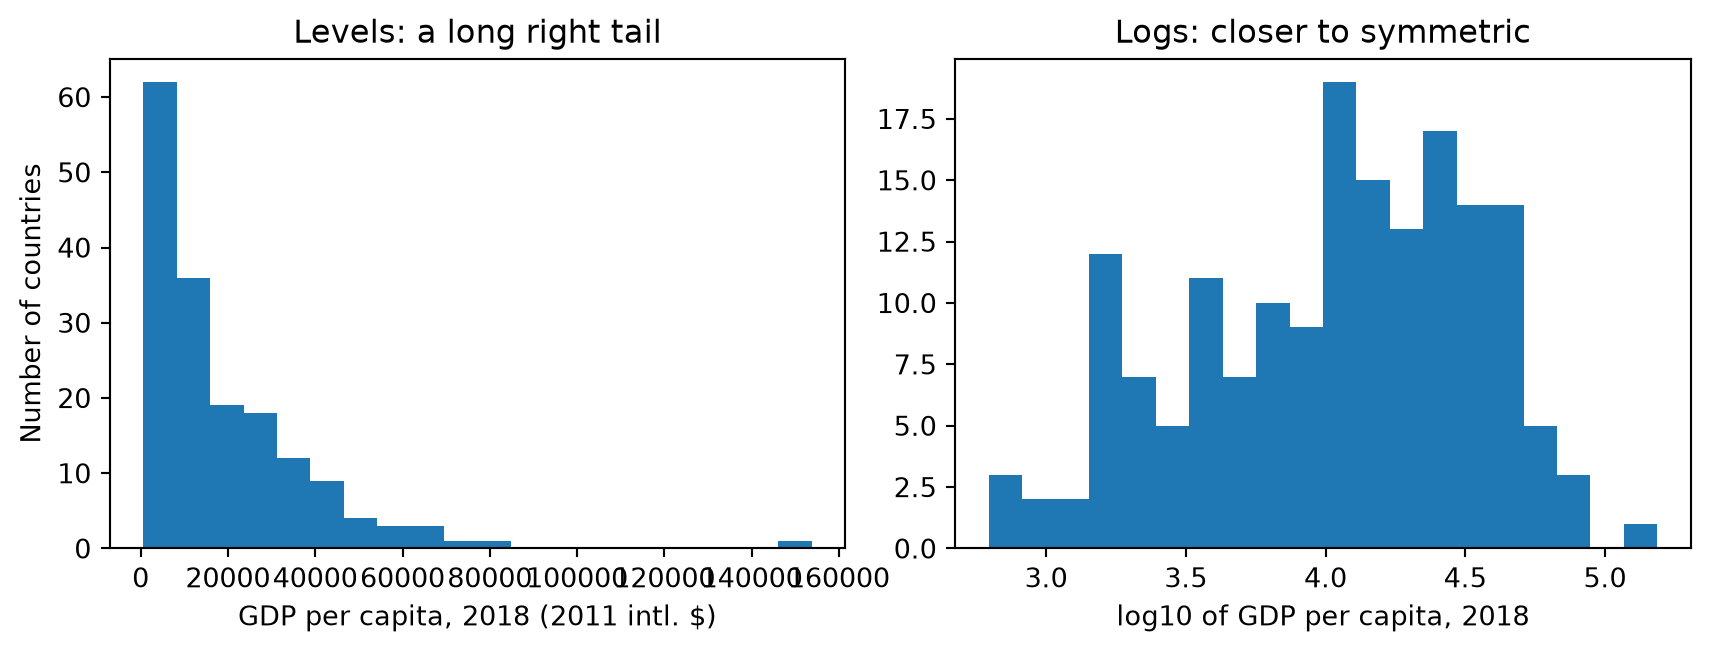

{0.1: 1728.0, 0.5: 12310.0, 0.9: 44705.0}   90th/10th percentile ratio: 25.9


In [3]:
y2018 = mpd[mpd["year"] == 2018].dropna(subset=["gdppc"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))
ax1.hist(y2018["gdppc"], bins=20)
ax1.set_xlabel("GDP per capita, 2018 (2011 intl. $)")
ax1.set_ylabel("Number of countries")
ax1.set_title("Levels: a long right tail")

ax2.hist(np.log10(y2018["gdppc"]), bins=20)
ax2.set_xlabel("log10 of GDP per capita, 2018")
ax2.set_title("Logs: closer to symmetric")
fig.tight_layout()
plt.show()

q = y2018["gdppc"].quantile([0.1, 0.5, 0.9])
print(q.round(0).to_dict(), f"  90th/10th percentile ratio: {q[0.9] / q[0.1]:.1f}")

In levels, most countries are bunched at low and middle incomes and a few are far out to the right. In logs, the shape is closer to symmetric, because the gap between \$2,000 and \$4,000 matters about as much as the gap between \$20,000 and \$40,000: **equal ratios are equal distances**. The 90th-percentile country is many times richer than the 10th-percentile country.

## 3. A variable over time, and why logs

A straight line on a **log scale** is a constant growth rate. Compare the same US series on both scales, with a dashed line showing constant 2% annual growth from 1850:

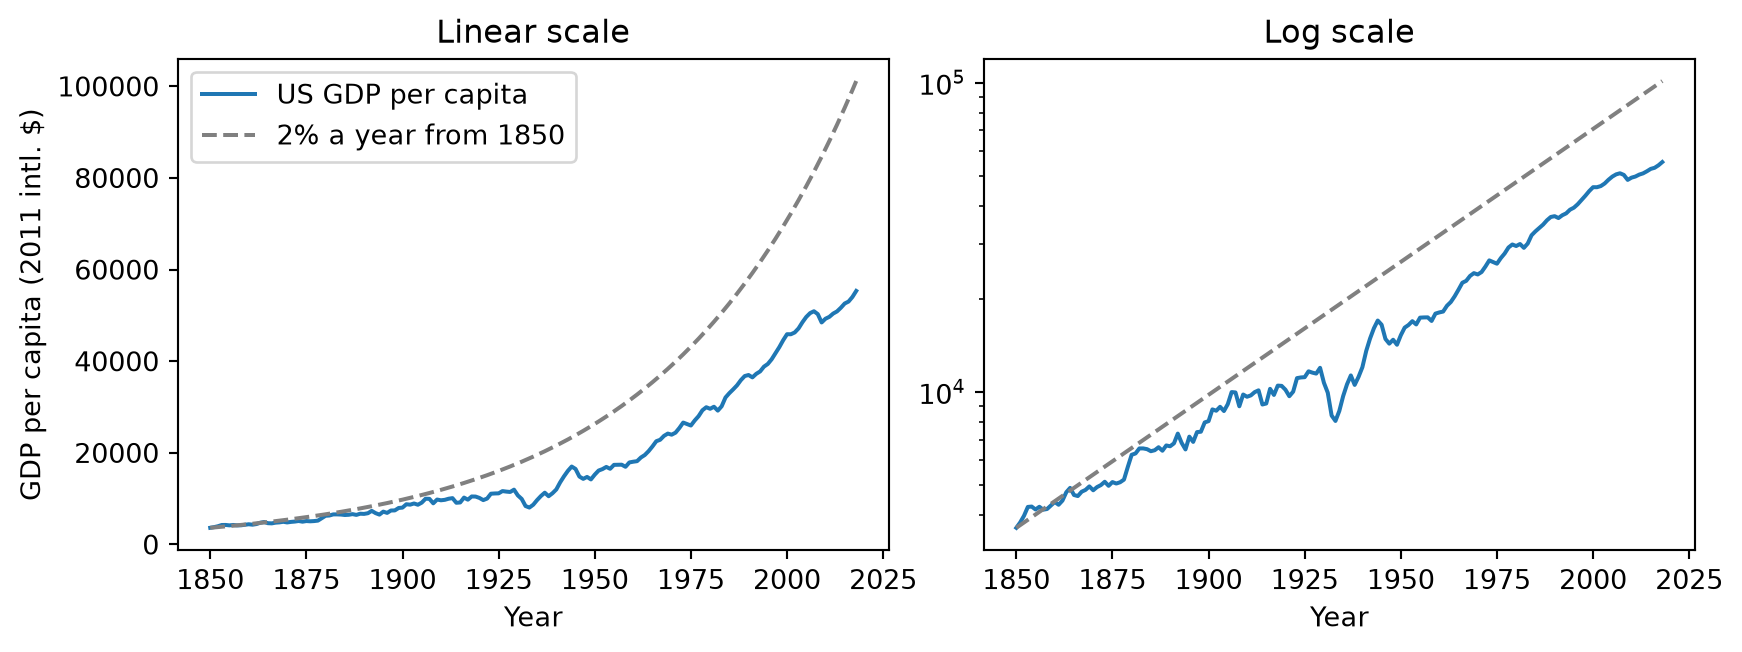

average growth 1850-2018: 1.62% a year


In [4]:
usa = mpd[(mpd["countrycode"] == "USA") & (mpd["year"] >= 1850)].sort_values("year")
g_avg = (np.log(usa["gdppc"].iloc[-1]) - np.log(usa["gdppc"].iloc[0])) / (usa["year"].iloc[-1] - usa["year"].iloc[0])
two_pct = usa["gdppc"].iloc[0] * 1.02 ** (usa["year"] - 1850)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, scale in zip(axes, ["linear", "log"]):
    ax.plot(usa["year"], usa["gdppc"], label="US GDP per capita")
    ax.plot(usa["year"], two_pct, "--", color="gray", label="2% a year from 1850")
    ax.set_yscale(scale)
    ax.set_xlabel("Year")
    ax.set_title(f"{scale.capitalize()} scale")
axes[0].set_ylabel("GDP per capita (2011 intl. $)")
axes[0].legend()
fig.tight_layout()
plt.show()
print(f"average growth 1850-2018: {100 * g_avg:.2f}% a year")

On the linear scale the curve looks like it takes off around 1950, even though growth was steady. On the log scale the US series stays close to a straight line, a little flatter than the 2% reference line (the cell prints the average, about 1.6% a year): its long-run growth rate barely changed, and the dips (the early 1930s, the 1940s) stand out. Use a log scale whenever **rates of change** are the story, and label the axis so the reader knows.

## 4. Comparing several series

Many lines need two decisions: put the lines on a log scale if you care about growth, and **label the lines directly** so the reader doesn't have to match colors to a legend. Choose readable tick labels:

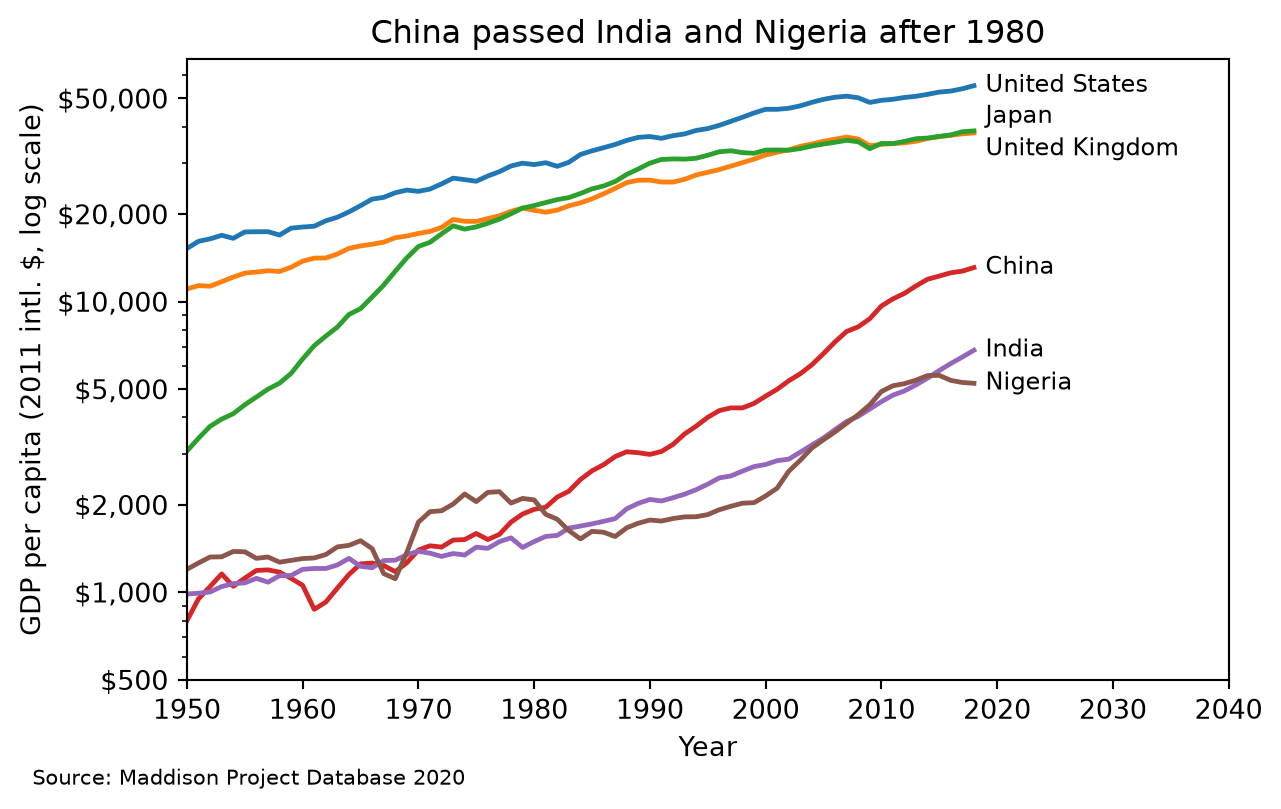

In [5]:
countries = ["United States", "United Kingdom", "Japan", "China", "India", "Nigeria"]
wide = mpd.pivot(index="year", columns="country", values="gdppc").loc[1950:, countries]

fig, ax = plt.subplots(figsize=(7, 4.2))
nudge = {"United Kingdom": 0.88, "Japan": 1.12}            # two end values are almost equal: separate the labels
for name in countries:
    ax.plot(wide.index, wide[name], linewidth=1.8)
    ax.text(2019, wide[name].iloc[-1] * nudge.get(name, 1.0), name, va="center", fontsize=9)   # label at the end of each line

ax.set_yscale("log")
ax.set_yticks([500, 1000, 2000, 5000, 10000, 20000, 50000])
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_xlim(1950, 2040)
ax.set_xlabel("Year")
ax.set_ylabel("GDP per capita (2011 intl. $, log scale)")
ax.set_title("China passed India and Nigeria after 1980")
fig.text(0.01, -0.02, "Source: Maddison Project Database 2020", fontsize=8)
plt.show()

Reading a log-scale line: the steeper the line, the faster the growth, whatever the level. China starts below India and Nigeria in 1950 and ends well above both. Extra room on the right (`set_xlim`) makes space for the labels, and where two end values are nearly equal (the United Kingdom and Japan) the labels are nudged apart.

## 5. Comparing groups

Our small lookup table assigns 26 countries to regions. With only a few countries per region, a box plot has too little to summarize; **show every country** as a point instead. A log axis keeps the poorest and richest regions on one picture.

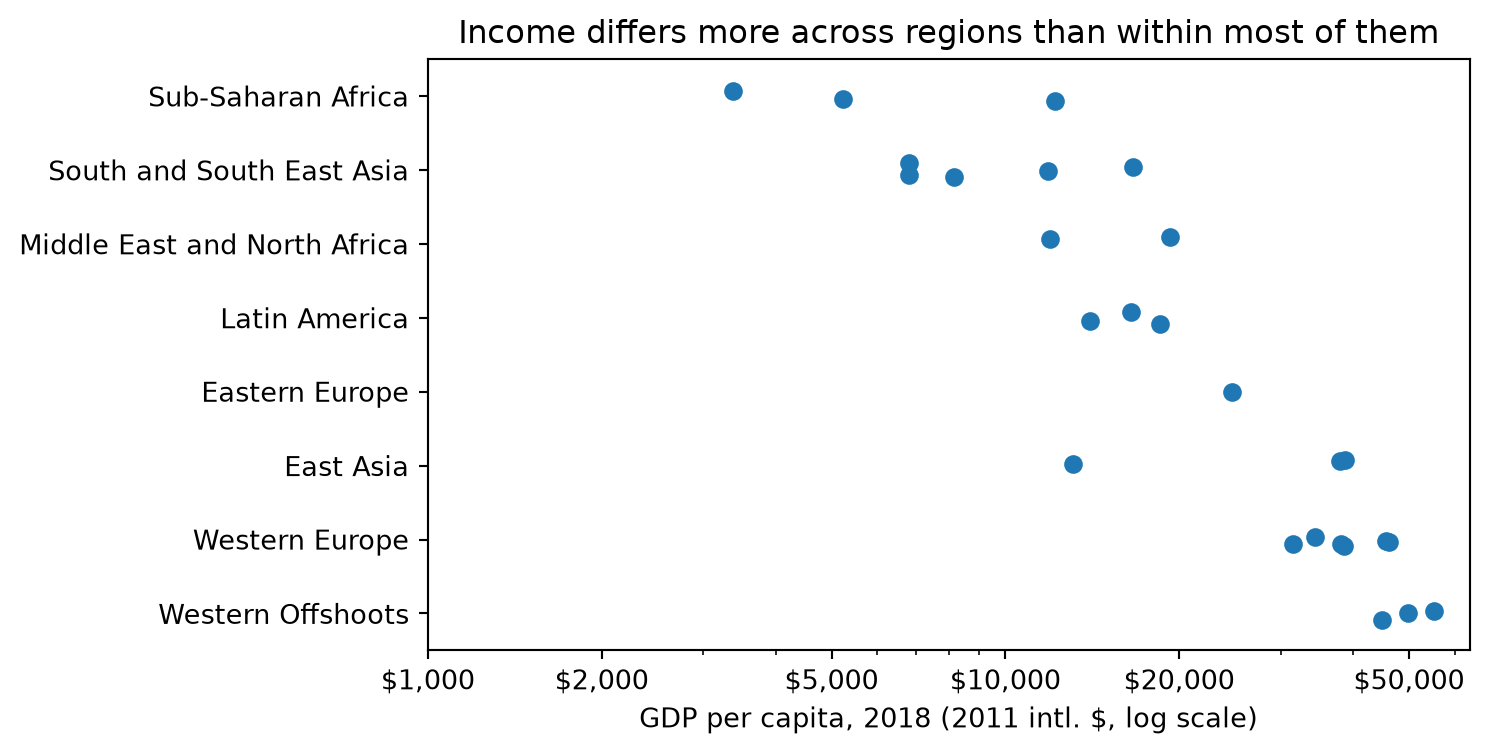

,count,min,max
region,,,
Sub-Saharan Africa,3,3377.0,12166.0
South and South East Asia,5,6806.0,16649.0
Middle East and North Africa,2,11957.0,19270.0
Latin America,3,14034.0,18556.0
Eastern Europe,1,24669.0,24669.0
East Asia,3,13102.0,38674.0
Western Europe,6,31497.0,46178.0
Western Offshoots,3,44869.0,55335.0


In [6]:
reg = y2018.merge(groups, on="countrycode", how="inner")
order = reg.groupby("region")["gdppc"].median().sort_values().index

fig, ax = plt.subplots(figsize=(7, 4))
sns.stripplot(data=reg, x="gdppc", y="region", order=order, size=7, ax=ax)
ax.set_xscale("log")
ax.set_xticks([1000, 2000, 5000, 10000, 20000, 50000])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("GDP per capita, 2018 (2011 intl. $, log scale)")
ax.set_ylabel("")
ax.set_title("Income differs more across regions than within most of them")
plt.show()
reg.groupby("region")["gdppc"].agg(["count", "min", "max"]).loc[order].round(0)

Check the title against the numbers before you keep it: compare the spread inside a region (min to max) with the gap between regions. If the claim doesn't hold, change the title, not the data.

## 6. Two variables: a scatter plot

Do poorer countries grow faster? In 1990, countries varied in income. If poor countries catch up, those with low 1990 income should show higher growth from 1990 to 2018. Each point is a country; both axes use logs (growth is already a log difference).

169 countries; slope -0.02 percentage points per unit of log income; correlation -0.01


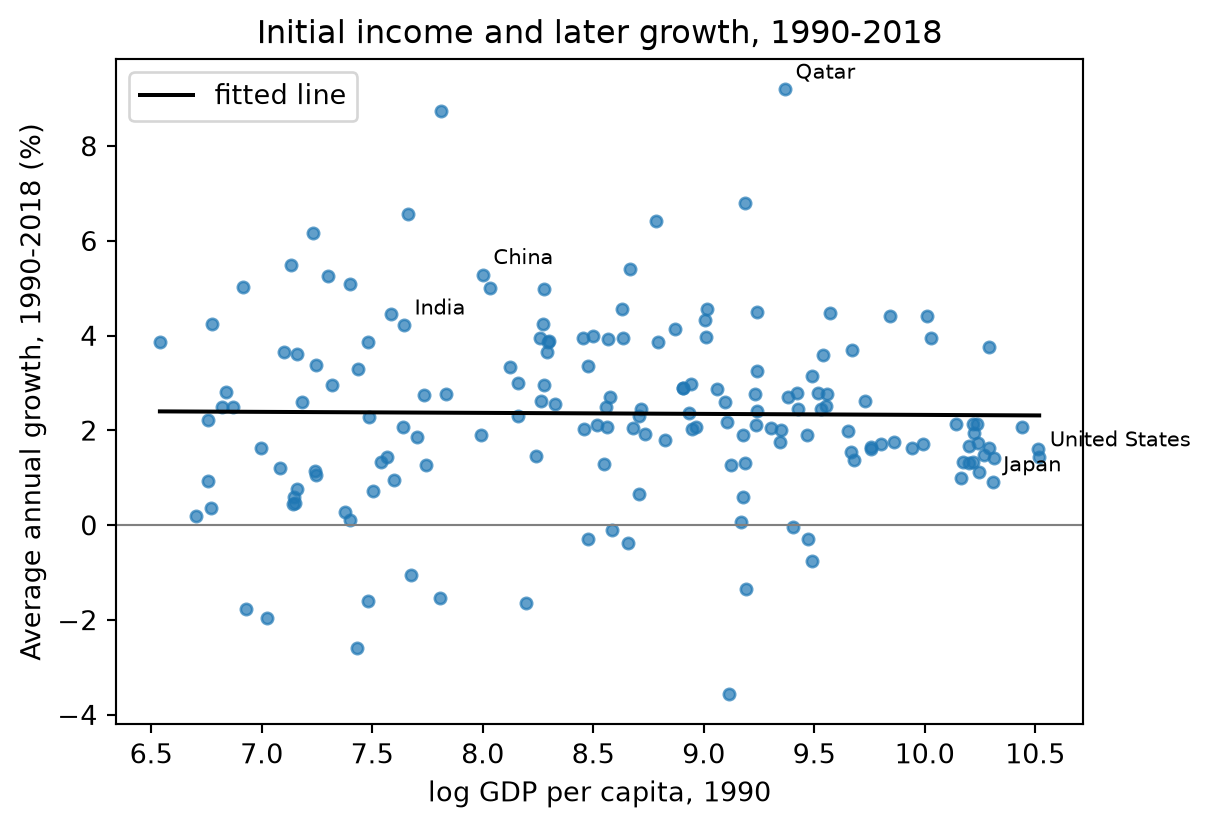

In [7]:
w = mpd.pivot(index="year", columns="country", values="gdppc")
conv = pd.DataFrame({"log_y1990": np.log(w.loc[1990]),
                     "growth": (np.log(w.loc[2018]) - np.log(w.loc[1990])) / 28 * 100}).dropna()

slope, intercept = np.polyfit(conv["log_y1990"], conv["growth"], 1)
r = np.corrcoef(conv["log_y1990"], conv["growth"])[0, 1]
print(f"{len(conv)} countries; slope {slope:.2f} percentage points per unit of log income; correlation {r:.2f}")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(conv["log_y1990"], conv["growth"], s=18, alpha=0.7)
xs = np.linspace(conv["log_y1990"].min(), conv["log_y1990"].max(), 50)
ax.plot(xs, intercept + slope * xs, color="black", linewidth=1.5, label="fitted line")
for name in ["China", "India", "United States", "Qatar", "Japan"]:
    ax.annotate(name, (conv.loc[name, "log_y1990"], conv.loc[name, "growth"]), fontsize=8,
                xytext=(4, 4), textcoords="offset points")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("log GDP per capita, 1990")
ax.set_ylabel("Average annual growth, 1990-2018 (%)")
ax.set_title("Initial income and later growth, 1990-2018")
ax.legend()
plt.show()

The fitted line is almost flat: across all 169 countries, 1990 income says essentially nothing about growth over the next 28 years. That is not what a simple "poor countries catch up" story predicts. It does not rule out catching up among countries that are alike in other ways, which is what economists usually test, with regression (Week 14). A fitted line is a **summary of the pattern**, not a law, and a different window or sample can change it. Notice how much the result depends on which of the 169 rows you include.

## 7. Adding context: recessions in a time series

`us_macro_1959_2009.csv` is quarterly US data, and `nber_recessions.csv` lists the eight recessions dated by the National Bureau of Economic Research. Shading the recessions shows how a variable behaves around them. `ax.axvspan(start, end)` draws a vertical band.

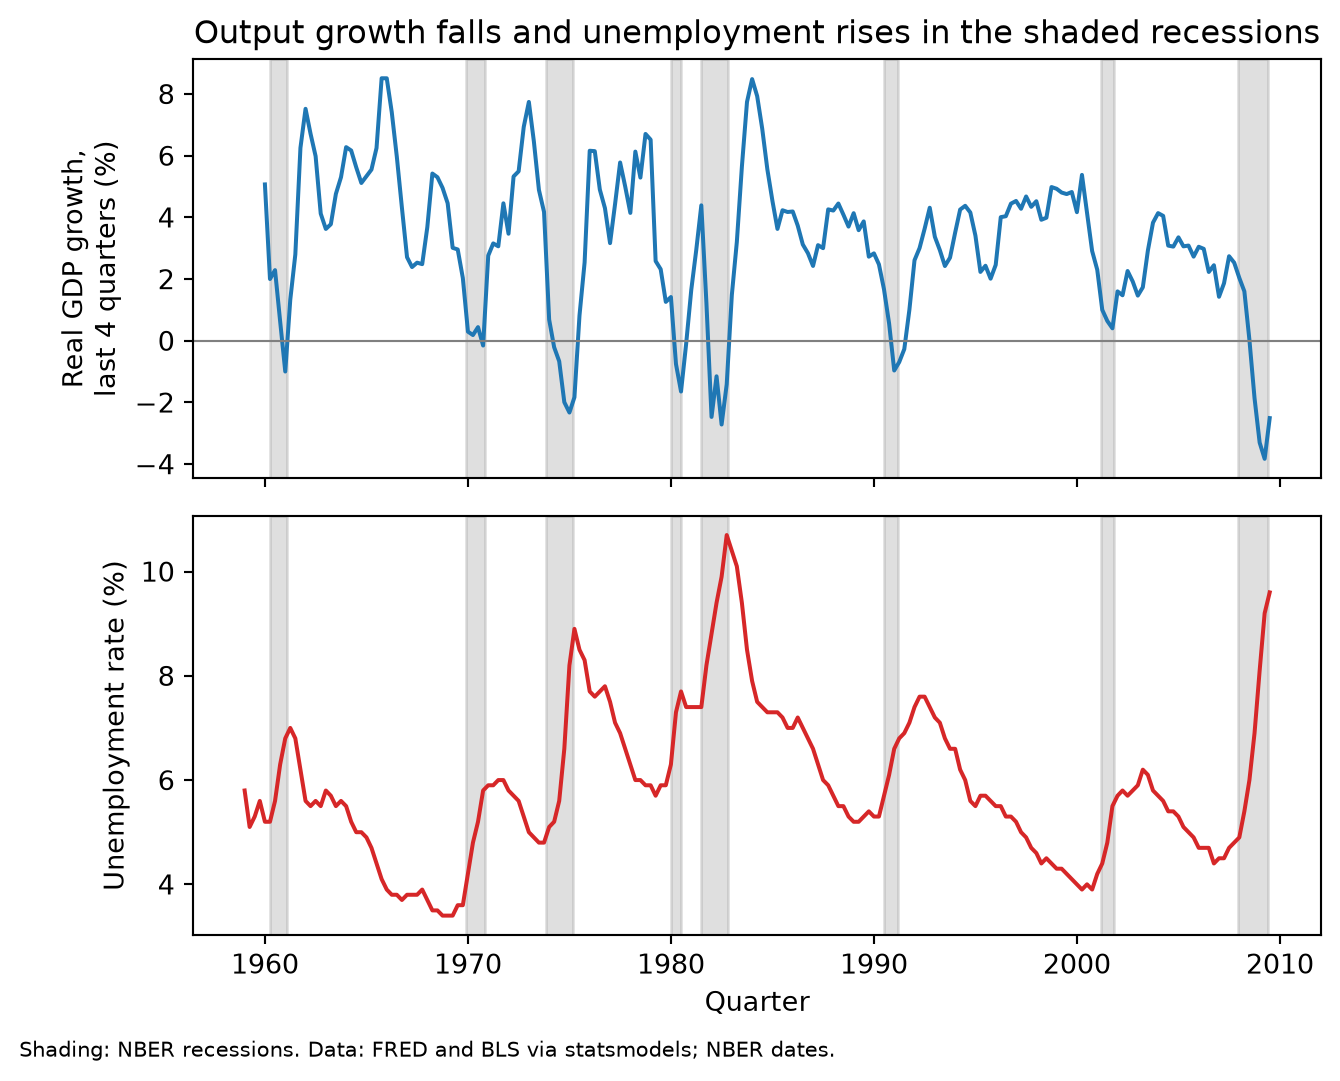

In [8]:
us = pd.read_csv(f"{DATA}/us_macro_1959_2009.csv")
us["date"] = pd.PeriodIndex.from_fields(year=us["year"], quarter=us["quarter"], freq="Q").to_timestamp()
us = us.set_index("date")
us["gdp_growth"] = us["realgdp"].pct_change(4) * 100

rec = pd.read_csv(f"{DATA}/nber_recessions.csv", parse_dates=["peak_month", "trough_month"])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 5.5), sharex=True)
ax1.plot(us.index, us["gdp_growth"], color="tab:blue")
ax1.axhline(0, color="gray", linewidth=0.8)
ax1.set_ylabel("Real GDP growth,\nlast 4 quarters (%)")
ax2.plot(us.index, us["unemp"], color="tab:red")
ax2.set_ylabel("Unemployment rate (%)")
ax2.set_xlabel("Quarter")
for ax in (ax1, ax2):
    for row in rec.itertuples():
        ax.axvspan(row.peak_month, row.trough_month, color="gray", alpha=0.25)
ax1.set_title("Output growth falls and unemployment rises in the shaded recessions")
fig.text(0.01, -0.01, "Shading: NBER recessions. Data: FRED and BLS via statsmodels; NBER dates.", fontsize=8)
fig.tight_layout()
plt.show()

A claim like "unemployment rises in every recession" is easy to check once you have the dates. Compare the unemployment rate in the quarter of each peak and each trough:

In [9]:
peak_u = [us.loc[pd.Period(q).start_time, "unemp"] for q in rec["peak_quarter"]]
trough_u = [us.loc[pd.Period(q).start_time, "unemp"] for q in rec["trough_quarter"]]
check = pd.DataFrame({"peak": rec["peak_quarter"], "trough": rec["trough_quarter"],
                      "unemp_at_peak": peak_u, "unemp_at_trough": trough_u})
check["change"] = (check["unemp_at_trough"] - check["unemp_at_peak"]).round(1)
check

,peak,trough,unemp_at_peak,unemp_at_trough,change
0,1960Q2,1961Q1,5.2,6.8,1.6
1,1969Q4,1970Q4,3.6,5.8,2.2
2,1973Q4,1975Q1,4.8,8.2,3.4
3,1980Q1,1980Q3,6.3,7.7,1.4
4,1981Q3,1982Q4,7.4,10.7,3.3
5,1990Q3,1991Q1,5.7,6.6,0.9
6,2001Q1,2001Q4,4.2,5.5,1.3
7,2007Q4,2009Q2,4.8,9.2,4.4


Unemployment was higher at the trough than at the peak in every one of the eight recessions, by 0.9 percentage points (1990-91) to 4.4 (2007-09). (The NBER trough dates the bottom of output, not unemployment; unemployment often keeps rising for a while after.)

## 8. Making a figure someone else will read

Everything from Week 3's checklist still applies. For figures with data, add:

- **Say what the axis is:** units, and "log scale" if it is.
- **Show the source**, on the figure or in a caption.
- **Label lines directly** when there are more than three or four.
- **Show the data points** when there are few of them.
- **Make the title the finding**, and check that the figure supports it.
- **Choose the figure for the question:** distribution (histogram), change over time (line), comparison across groups (points or bars), relationship (scatter).

### Stating the finding

A finding is a sentence with a number in it, the evidence, and a caveat. You can build it from variables, so the text always matches the computation:

In [10]:
d = conv["growth"]
display(Markdown(
    f"**Finding.** Between 1990 and 2018 the median country's GDP per capita grew {d.median():.1f}% a year "
    f"({len(conv)} countries), and the fitted line of growth on 1990 income has a slope of {slope:.2f}. "
    f"*Caveat:* the line is nearly flat (correlation {r:.2f}), so 1990 income does not predict growth in this sample; it says nothing about catching up among similar countries."
))

**Finding.** Between 1990 and 2018 the median country's GDP per capita grew 2.2% a year (169 countries), and the fitted line of growth on 1990 income has a slope of -0.02. *Caveat:* the line is nearly flat (correlation -0.01), so 1990 income does not predict growth in this sample; it says nothing about catching up among similar countries.

## 9. In-class lab

The exercises for this week are in **Lab 5**. It appears in the `lab05` folder of your repository at the start of the second class session (pull to see it), and you work on it in pairs.

## This week

- Read [FC 2. Long-Run Growth](https://intro.quantecon.org/long_run_growth.html) from *A First Course in Quantitative Economics with Python*.
- **PS05** (growth and recessions in figures) is in the `ps05` folder of your repo.
- Module 3 starts next week: solving models numerically.